# Assignment 1: K-Means Clustering on Iris Dataset

## Objective
Apply the K-Means clustering algorithm to the Iris dataset and visualize the resulting clusters.

## Tasks
- Load and explore the Iris dataset.
- Standardize the features.
- Apply K-Means clustering with 3 clusters.
- Display the cluster centers.
- Visualize the clusters using a scatter plot.
- Compare the predicted clusters with the actual species labels.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [2]:
iris = load_iris()

X = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

y = iris.target

X.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [3]:
print("Dataset shape:", X.shape)
print("Feature names:", X.columns.tolist())
print("Species names:", iris.target_names)

print("\nMissing values:")
print(X.isnull().sum())

print("\nTarget distribution:")
print(pd.Series(y).value_counts().sort_index())

Dataset shape: (150, 4)
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Species names: ['setosa' 'versicolor' 'virginica']

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64

Target distribution:
0    50
1    50
2    50
Name: count, dtype: int64


In [4]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Original data shape:", X.shape)
print("Scaled data shape:", X_scaled.shape)

print("\nFirst 5 scaled rows:")
print(X_scaled[:5])

Original data shape: (150, 4)
Scaled data shape: (150, 4)

First 5 scaled rows:
[[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]
 [-1.38535265  0.32841405 -1.39706395 -1.3154443 ]
 [-1.50652052  0.09821729 -1.2833891  -1.3154443 ]
 [-1.02184904  1.24920112 -1.34022653 -1.3154443 ]]


In [30]:
kmeans = KMeans(
    n_clusters=3,
    random_state=43,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

print("Predicted cluster labels:")
print(clusters)

print("\nCluster centers:")
print(kmeans.cluster_centers_)

Predicted cluster labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 0 0 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0
 0 2 2 2 0 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 2 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]

Cluster centers:
[[-0.05021989 -0.88337647  0.34773781  0.2815273 ]
 [-1.01457897  0.85326268 -1.30498732 -1.25489349]
 [ 1.13597027  0.08842168  0.99615451  1.01752612]]


C:\Users\pc\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


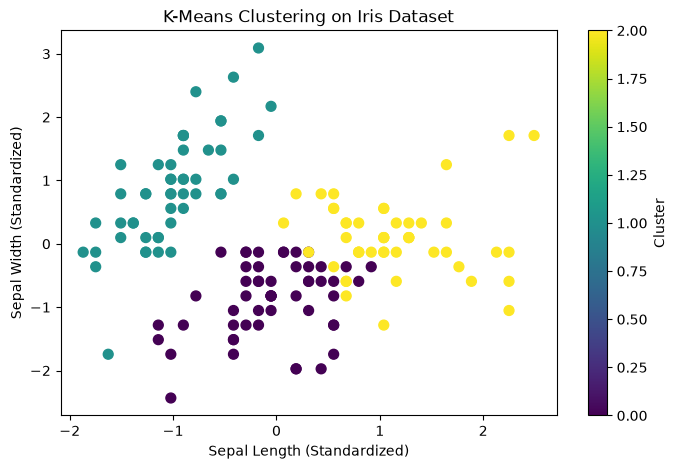

In [31]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap="viridis",
    s=50
)

plt.xlabel("Sepal Length (Standardized)")
plt.ylabel("Sepal Width (Standardized)")
plt.title("K-Means Clustering on Iris Dataset")
plt.colorbar(label="Cluster")
plt.show()

In [32]:
results = pd.DataFrame({
    "Actual Species": [iris.target_names[i] for i in y],
    "Predicted Cluster": clusters
})

print(results.head(10))

print("\nComparison of actual species and predicted clusters:")
print(pd.crosstab(
    results["Actual Species"],
    results["Predicted Cluster"]
))

  Actual Species  Predicted Cluster
0         setosa                  1
1         setosa                  1
2         setosa                  1
3         setosa                  1
4         setosa                  1
5         setosa                  1
6         setosa                  1
7         setosa                  1
8         setosa                  1
9         setosa                  1

Comparison of actual species and predicted clusters:
Predicted Cluster   0   1   2
Actual Species               
setosa              0  50   0
versicolor         39   0  11
virginica          14   0  36


In [33]:
from sklearn.metrics import adjusted_rand_score

ari = adjusted_rand_score(y, clusters)

print("Adjusted Rand Index:", round(ari, 3))

Adjusted Rand Index: 0.62


## Conclusion

The K-Means clustering algorithm was applied to the Iris dataset using three clusters. The dataset features were standardized before clustering to ensure that differences in feature scales did not disproportionately influence the distance calculations. The resulting clusters were visualized using a scatter plot and compared with the actual Iris species labels. The Adjusted Rand Index was used to evaluate the agreement between the predicted clusters and actual species. This experiment demonstrates how an unsupervised learning algorithm can discover patterns and group similar data points without using the true labels during training.